# 10 · Knowledge base: corpus, hybrid retrieval, abstention and evaluation

**FinGuard AI, Phase 3.** Run `python -m finguard.rag build` and `python -m finguard.rag evaluate`
first; this notebook reads their outputs and shows the `policy_search` tool.

The knowledge base answers three questions about an alert: what the pattern means, what to
check next, and what the institution's obligations are if fraud is confirmed. It does not
"verify a transaction against regulation". Exit criteria (Project Report v3.0): Hit@5 >= 0.80
and at least 8 of 10 unanswerable questions answered "not covered by the sources".

In [1]:
import sys, pathlib, json
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from finguard import config
from finguard.evaluation import figures as F
from finguard.rag import corpus, evaluate as ev
from finguard.rag.text import approx_tokens

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 110)
T = config.TABLE_DIR
reg = pd.DataFrame(corpus.load_registry())
build = json.loads((corpus.INDEX_DIR / "build_report.json").read_text(encoding="utf-8"))
index = corpus.load_index()
print(f"index {index.version} | embedder {index.embedder.name} | {len(index.chunks):,} chunks")

Loading weights: 100%|##########| 199/199 [00:00<00:00, 1334.43it/s]
index e625b14c7e7c862f | embedder intfloat/multilingual-e5-small | 657 chunks


## 1. The corpus
Every document has a registry entry (publisher, date, jurisdiction, tier, language, URL and
SHA-256). Published documents are checked against their recorded hash on every build.

In [2]:
docs = pd.DataFrame(build["documents"]).merge(reg[["doc_id", "title", "publisher", "published", "jurisdiction", "tier", "language", "sha256"]],
                                              on="doc_id", how="right")
docs["sha256"] = docs.sha256.fillna("").str[:12]
print("missing documents:", [m["doc_id"] for m in build["missing"]] or "none", "| hash mismatches:", build["hash_mismatch"] or "none")
docs[["doc_id", "publisher", "published", "jurisdiction", "tier", "language", "pages", "headings", "tables", "chunks", "sha256"]]

missing documents: none | hash mismatches: none


,doc_id,publisher,published,jurisdiction,tier,language,pages,headings,tables,chunks,sha256
0,eba_ecb_payment_fraud_2025,European Banking Authority and European Central Bank,2025-12,EU,1,en,49.0,21,43,99,30b57d58f5ce
1,eba_gl_2018_05,European Banking Authority,2018-07-18,EU,1,en,140.0,73,123,215,a6d5c98045e1
2,fatf_cyber_enabled_fraud_2023,"FATF, INTERPOL and Egmont Group",2023-11,International,1,en,4.0,8,0,4,e329cc57c583
3,visa_dispute_management,Visa,2026-10,Card network (international),1,en,112.0,294,0,108,bb3acc67569f
4,frb_fraudclassifier,Federal Reserve (FedPayments Improvement),2020-06,US,1,en,3.0,0,4,5,73907ac5afbc
5,frb_fraud_scam_together,Federal Reserve (FedPayments Improvement),2026-03,US,1,en,6.0,2,13,4,9ad013f7b678
6,fatf_recommendations,Financial Action Task Force,2026-06,International,2,en,151.0,356,33,172,3c2553430fdf
7,bct_circulaire_2017_08,Banque Centrale de Tunisie,2017-09-19,TN,3,fr,16.0,77,0,33,2442b9145309
8,finguard_data_glossary,FinGuard project team,2026-10-29,Dataset,1,en,NaN,9,3,4,fb4581a44639
9,finguard_feature_reason_glossary,FinGuard project team,2026-10-29,Project,1,en,NaN,11,6,8,8020d6e4c82c


In [3]:
sizes = pd.Series([approx_tokens(c["text"]) for c in index.chunks])
kinds = pd.Series([c["kind"] for c in index.chunks]).value_counts()
print("chunk size (approximate tokens):", sizes.describe(percentiles=[0.1, 0.5, 0.9]).round(0).to_dict())
print("chunk kinds:", kinds.to_dict())
print("share of text chunks within 300-500 tokens:",
      f"{((sizes >= 300) & (sizes <= 500))[pd.Series([c['kind'] == 'text' for c in index.chunks])].mean():.1%}")

chunk size (approximate tokens): {'count': 657.0, 'mean': 349.0, 'std': 123.0, 'min': 1.0, '10%': 165.0, '50%': 385.0, '90%': 479.0, 'max': 736.0}
chunk kinds: {'text': 449, 'table': 208}
share of text chunks within 300-500 tokens: 74.4%


## 2. The question set
Written before the index was evaluated and frozen by hash. Each answerable question names
its gold passage by document and a quoted span; unanswerable questions are in the domain but
not covered by the corpus.

In [4]:
frozen = ev.check_frozen()
qs = pd.DataFrame(ev.load_questions())
qs["gold_doc"] = qs.gold.map(lambda g: g[0]["doc_id"] if g else "(none)")
print("frozen:", frozen)
pd.crosstab(qs.gold_doc, [qs.answerable, qs.split], margins=True)

frozen: {'sha256': '3331371148a215e38edc9fdfd8ec8d660280adafff610f036052d852d5ec668b', 'frozen_at': '2026-10-29 14:23:11', 'n_questions': 60, 'note': "written from the documents' text after parsing, before any retrieval run; gold quotes checked against chunks only"}


answerable                       False      True      All
split                              dev test  dev test    
gold_doc                                                 
(none)                               5    5    0    0  10
bct_circulaire_2017_08               0    0    3    2   5
eba_ecb_payment_fraud_2025           0    0    3    3   6
eba_gl_2018_05                       0    0    3    3   6
fatf_cyber_enabled_fraud_2023        0    0    2    1   3
fatf_recommendations                 0    0    4    4   8
finguard_data_glossary               0    0    2    1   3
finguard_feature_reason_glossary     0    0    2    2   4
finguard_investigation_playbook      0    0    2    1   3
frb_fraud_scam_together              0    0    1    1   2
frb_fraudclassifier                  0    0    1    1   2
visa_dispute_management              0    0    4    4   8
All                                  5    5   27   23  60

## 3. Every evaluation of the frozen set
The question set was frozen before the first evaluation. Fixes after it were chosen by
reading misses on the development half only; the held-out half is reported each time but
never used to choose. Run 3 is kept although it was replaced: it shows an abstention rule
that fitted the five development unanswerables and failed on the held-out ones.

In [5]:
runs = json.loads((T / "phase3_retrieval_runs.json").read_text(encoding="utf-8"))
log = []
for r in runs:
    v = r.get("chosen_variant") or "hybrid_rerank"                 # runs 1-4 used hybrid + re-ranking throughout
    s = {x["variant"]: x for x in r["summary"]}[v]
    sp = {x["split"]: x["hit_at_5"] for x in (r["by_split"] or []) if x["variant"] == v}
    ab = r["abstention"]
    log.append({"run": r["run"], "variant": v, "hit@5 all": s["hit_at_5"], "hit@5 dev": sp.get("dev"), "hit@5 test": sp.get("test"),
                "abstained (of 10)": ab["all"]["correct_abstentions"], "false abstentions (of 50)": ab["all"].get("false_abstentions"),
                "what changed": r["note"]})
pd.DataFrame(log).set_index("run")

,variant,hit@5 all,hit@5 dev,hit@5 test,abstained (of 10),false abstentions (of 50),what changed
run,,,,,,,
1,hybrid_rerank,0.76,NaN,NaN,9,6,"first evaluation of the frozen set: initial parser and tokenizer, threshold-only abstention"
2,hybrid_rerank,0.80,0.815000,0.783000,8,9,"parser fixes found on dev misses (running header in small type, heading-sized 'Guideline N: title' lines k..."
3,hybrid_rerank,0.80,0.814815,0.782609,7,1,grounding check added to abstention (names in the question must appear in the returned passages); threshol...
4,hybrid_rerank,0.80,0.814815,0.782609,9,9,"abstention rule fixed: threshold tuned on dev alone (as in runs 1-2), combined with the parameter-free gro..."
5,bm25,0.80,0.814815,0.782609,9,16,chunking brought to the 300-500 token design: sub-sections under 300 tokens absorb the next one (headings ...
6,bm25,0.80,0.814815,0.782609,9,16,"evaluation fix: confidence is now measured over the top 5 passages the tool returns, as the grounding chec..."
7,bm25,0.80,0.814815,0.782609,8,4,neural embedder and cross-encoder


## 4. Retrieval variants
The keyword, vector, fused and re-ranked variants on the answerable questions. In this build
environment the dense model is LSA (TF-IDF + SVD) and the re-ranker is the lexical blend,
because no embedding or cross-encoder model could be downloaded; with `FINGUARD_EMBEDDER`
and `FINGUARD_RERANKER` set, the same evaluation compares the neural ones. The variant is
chosen on the development half: the simplest one at or above 0.80 there (the rule written in
`rag/retrieve.py` before the first run), and `policy_search` uses it.

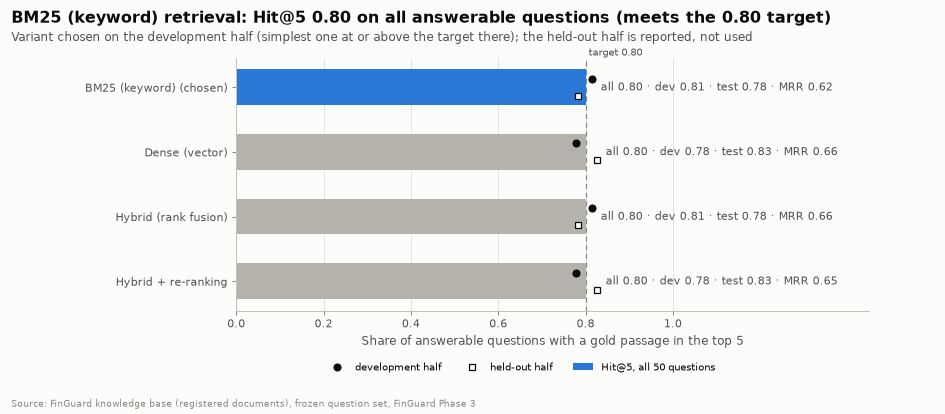

,variant,questions,hit_at_1,hit_at_5,doc_at_5,mrr_at_10
0,bm25,50,0.50,0.8,0.98,0.619
1,dense,50,0.56,0.8,0.98,0.662
2,hybrid,50,0.54,0.8,0.98,0.656
3,hybrid_rerank,50,0.56,0.8,0.98,0.651


In [6]:
res = json.loads((T / "phase3_retrieval_results.json").read_text(encoding="utf-8"))
summary = pd.DataFrame(res["summary"])
by_split = pd.DataFrame(res["by_split"])
chosen = res["chosen_variant"]
fig = F.fig27_retrieval(summary, by_split, chosen)
summary.round(3)

In [7]:
def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h

det = pd.read_csv(T / "phase3_retrieval_details.csv")
rows = []
for part, sel in [("dev", det.split == "dev"), ("test", det.split == "test"), ("all", det.split.notna())]:
    a = det[sel & det.answerable & (det.variant == chosen)]
    k, n = int(a["hit@5"].sum()), len(a)
    lo, hi = wilson(k, n)
    rows.append({"half": part, "questions": n, "gold in top 5": k, "hit@5": round(k / n, 3), "95% interval": f"{lo:.2f}-{hi:.2f}",
                 "doc@5": round(a["doc@5"].mean(), 3)})
print("chosen on the development half:", chosen)
pd.DataFrame(rows).set_index("half")

chosen on the development half: bm25


,questions,gold in top 5,hit@5,95% interval,doc@5
half,,,,,
dev,27,22,0.815,0.63-0.92,0.963
test,23,18,0.783,0.58-0.90,1.000
all,50,40,0.800,0.67-0.89,0.980


Hit@5 is exactly at the target on all 50 questions and the interval is wide: with 23
held-out questions one question moves Hit@5 by 0.04. All four variants reach 0.80 overall;
they differ in how high the gold passage ranks (MRR). Doc@5 (the gold document among the top
five) is close to 1, so most misses retrieve the right document but a neighbouring passage.

## 5. Abstention
Two checks, either of which abstains: a name in the question (a scheme, country, body or
identifier) appears in none of the returned passages or their document's metadata; or the
confidence is below a threshold tuned on the development half alone.

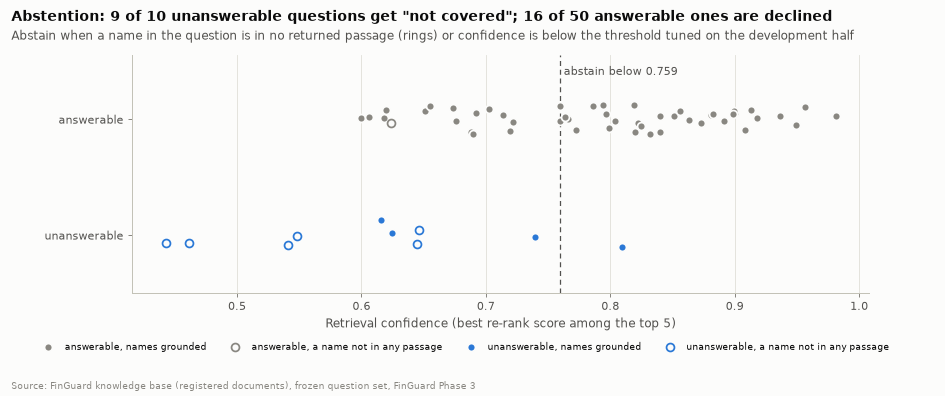

,threshold,dev abstained,test abstained,all abstained,false abstentions (all),hit@5 after abstention
rule,,,,,,
chosen: names + threshold,0.759,5/5,4/5,9/10,16/50,0.6
ablation: threshold only,0.759,5/5,4/5,9/10,16/50,0.6
ablation: grounding only,0.000,4/5,2/5,6/10,1/50,0.8
ablation: jointly tuned,0.000,4/5,2/5,6/10,1/50,0.8


In [8]:
ab = res["abstention"]
a = det[det.variant == ab["variant"]].reset_index(drop=True)
flagged = a.ungrounded.fillna("").str.len().gt(0).to_numpy()
fig = F.fig28_abstention(a.confidence.to_numpy(), a.answerable.to_numpy(), flagged, ab["threshold"],
                         ab["all"]["correct_abstentions"], ab["all"]["unanswerable"], ab["all"]["false_abstentions"],
                         ab["all"]["answerable"])
rules = {"chosen: names + threshold": ab, **{f"ablation: {k.replace('_', ' ')}": v for k, v in ab["ablations"].items()}}
pd.DataFrame([{"rule": name, "threshold": round(r["threshold"], 3),
               **{f"{h} abstained": f"{r[h]['correct_abstentions']}/{r[h]['unanswerable']}" for h in ("dev", "test", "all")},
               "false abstentions (all)": f"{r['all']['false_abstentions']}/{r['all']['answerable']}",
               "hit@5 after abstention": round(r["all"]["hit@5_after_abstention"], 3)} for name, r in rules.items()]).set_index("rule")

In [9]:
qtext = pd.DataFrame(ev.load_questions()).set_index("id").question
u = a[~a.answerable].assign(question=lambda d: d.id.map(qtext), abstained=lambda d: (d.confidence < ab["threshold"]) | d.ungrounded.notna())
u[["id", "split", "question", "confidence", "ungrounded", "abstained"]]

,id,split,question,confidence,ungrounded,abstained
50,u01,dev,What is the Mastercard reason code for card-not-present fraud chargebacks?,0.644723,Mastercard,True
51,u02,test,How many days does an American Express merchant have to respond to a fraud dispute?,0.541087,American|Express,True
52,u03,dev,What was the total value of card fraud in Tunisia in 2024?,0.646440,Tunisia,True
53,u04,test,What is the UK reimbursement limit for victims of authorised push payment scams?,0.624605,NaN,True
54,u05,dev,What interchange fee applies to a Visa debit card payment in the EU?,0.739770,NaN,True
55,u06,test,Which fraud-scoring vendor does the European Central Bank recommend to banks?,0.616002,NaN,True
56,u07,dev,How many suspicious transaction reports did the Tunisian CTAF receive in 2024?,0.461278,Tunisian|CTAF,True
57,u08,test,Which browser family has the highest fraud rate in the IEEE-CIS later period?,0.809637,NaN,False
58,u09,dev,What does the Mastercard Ethoca alert service do?,0.548541,Ethoca,True
59,u10,test,How long does a Visa issuer have to file a pre-arbitration in Tunisia under local law?,0.442728,Tunisia,True


The threshold is a trade-off between wrong answers and declined questions. The operating
points below (grounding check always on) let the team choose; the evaluation's rule picks the
best balanced accuracy on the development half.

In [10]:
ops = []
for t in sorted({0.0, 0.55, 0.60, 0.65, 0.70, round(ab["threshold"], 3)}):
    row = {"threshold": t}
    for h, sel in [("dev", a.split == "dev"), ("test", a.split == "test"), ("all", a.split.notna())]:
        x = a[sel]
        abstain = (x.confidence < t) | x.ungrounded.notna()
        row[f"{h}: abstained"] = f"{int((abstain & ~x.answerable).sum())}/{int((~x.answerable).sum())}"
        row[f"{h}: declined answerable"] = f"{int((abstain & x.answerable).sum())}/{int(x.answerable.sum())}"
    ops.append(row)
pd.DataFrame(ops).set_index("threshold")

,dev: abstained,dev: declined answerable,test: abstained,test: declined answerable,all: abstained,all: declined answerable
threshold,,,,,,
0.000,4/5,1/27,2/5,0/23,6/10,1/50
0.550,4/5,1/27,2/5,0/23,6/10,1/50
0.600,4/5,1/27,2/5,1/23,6/10,2/50
0.650,4/5,4/27,4/5,1/23,8/10,5/50
0.700,4/5,8/27,4/5,4/23,8/10,12/50
0.759,5/5,9/27,4/5,7/23,9/10,16/50


## 6. Where retrieval misses

In [11]:
miss = det[(det.variant == chosen) & det.answerable & ~det["hit@5"]].merge(qs[["id", "question", "gold_doc"]], on="id")
miss[["id", "split", "question", "gold_doc", "top_doc", "first_gold_rank", "doc@5"]]

,id,split,question,gold_doc,top_doc,first_gold_rank,doc@5
0,q02,test,What prior transactions are needed to use Compelling Evidence 3.0?,visa_dispute_management,visa_dispute_management,NaN,True
1,q03,dev,How recent must the earlier transactions be for a CE3.0 response?,visa_dispute_management,visa_dispute_management,NaN,True
2,q17,dev,Which fraudulent payment transactions must payment service providers report under the EBA fraud reporting ...,eba_gl_2018_05,eba_gl_2018_05,6.0,True
3,q19,dev,How often do payment service providers report fraud statistics under PSD2?,eba_gl_2018_05,eba_gl_2018_05,10.0,True
4,q20,test,What is meant by modification of a payment order by the fraudster?,eba_gl_2018_05,eba_gl_2018_05,NaN,True
5,q25,dev,Which fraud type makes up most of the value of fraudulent credit transfers?,eba_ecb_payment_fraud_2025,eba_ecb_payment_fraud_2025,10.0,True
6,q26,test,Does strong customer authentication reduce card fraud rates?,eba_ecb_payment_fraud_2025,eba_ecb_payment_fraud_2025,NaN,True
7,q30,test,Quelles fonctions doit offrir le système d'information de lutte contre le blanchiment ?,bct_circulaire_2017_08,bct_circulaire_2017_08,NaN,True
8,q33,dev,"Under the Tunisian central bank circular, may a bank keep a correspondent relationship with a shell bank?",bct_circulaire_2017_08,fatf_recommendations,NaN,False
9,q38,test,How does the FraudClassifier model define an authorized party that was manipulated?,frb_fraudclassifier,frb_fraudclassifier,8.0,True


## 7. The `policy_search` tool
What the agents will receive: cited passages labelled S1-S5, or "not covered by the sources"
with the names the sources do not mention.

In [12]:
from finguard.rag.tool import SCHEMA, policy_search
print(json.dumps(SCHEMA, indent=1))
examples = {}
for q, kw in [("What does Visa dispute condition 10.4 cover and what evidence can the merchant provide?", {}),
              ("Which FATF Recommendation requires reporting suspicious transactions?", {"tier": 2}),
              ("What is the Mastercard reason code for card-not-present fraud?", {}),
              ("What does the Mastercard Ethoca alert service do?", {})]:
    out = policy_search(q, **kw)
    examples[q] = {k: out[k] for k in ("status", "confidence", "ungrounded_names")} | {
        "passages": [{k: p[k] for k in ("label", "doc_id", "section", "pages")} for p in out["passages"][:3]]}
    print("\nQ:", q, "| status:", out["status"], "| confidence:", out["confidence"], "| ungrounded:", out["ungrounded_names"])
    if out["status"] != "ok":
        print("  ", out["message"])
    for p in out["passages"][:3]:
        print(f"  [{p['label']}] {p['title']} ({p['publisher']}, {p['published']}) | {p['section'][:70]} | pages {p['pages']}")
        if p["subsections"]:
            print("       also covers:", "; ".join(p["subsections"])[:150])
        print("      ", p["text"][:220].replace("\n", " "), "...")

{
 "name": "policy_search",
 "description": "Search the FinGuard knowledge base (card-not-present fraud guidance, dispute rules, AML/KYC obligations, project glossaries). Returns cited passages or 'not covered by the sources'.",
 "input_schema": {
  "type": "object",
  "properties": {
   "query": {
    "type": "string",
    "description": "What to look up, in plain words or with identifiers (e.g. 'Visa 10.4')."
   },
   "tier": {
    "type": "integer",
    "enum": [
     1,
     2,
     3
    ],
    "description": "1 = CNP fraud and system documents, 2 = AML/KYC, 3 = jurisdiction and internal."
   },
   "jurisdiction": {
    "type": "string",
    "description": "e.g. EU, International, US, TN, Dataset, Project."
   },
   "k": {
    "type": "integer",
    "minimum": 1,
    "maximum": 5,
    "default": 5
   }
  },
  "required": [
   "query"
  ]
 }
}
Loading weights: 100%|##########| 201/201 [00:00<00:00, 1071.81it/s]

Q: What does Visa dispute condition 10.4 cover and what evidence can t

In [13]:
phase3 = {"index_version": res["index_version"], "embedder": res["embedder"], "n_chunks": len(index.chunks),
          "documents": len(build["documents"]), "chosen_variant": chosen, "hit_at_5": rows, "summary": res["summary"],
          "by_split": res["by_split"], "abstention": {k: ab[k] for k in ("rule", "threshold", "dev", "test", "all")},
          "ablations": ab["ablations"], "misses": miss[["id", "split", "gold_doc", "top_doc", "first_gold_rank"]].to_dict("records"),
          "runs": log, "operating_points": ops, "tool_examples": examples}
(T / "phase3_summary.json").write_text(json.dumps(phase3, indent=1, default=float), encoding="utf-8")
print("saved reports/tables/phase3_summary.json")

saved reports/tables/phase3_summary.json
